# 03: How Much Is the Driver?

Put Max Verstappen in a Williams and he will not be on pole. Put a midfield driver in a Red Bull and
he probably will be, at least sometimes. This notebook puts numbers on that.

Notebook 01 decided what to measure: each driver's best lap in Q1, as a percentage gap to the fastest
lap of that session. If the fastest lap is 84.0s and a driver managed 84.8s, his gap is about 1%.
Notebook 02 fitted a model that splits that gap into three parts: the driver, the car he was in that
season, and the season itself. In its own notation,
`sqrt_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)`: a baseline lap, plus an offset per driver,
per team per season and per season, fitted on the square root of the gap.

This notebook answers the question the project was built around, and spends at least as much space on
how far the answer can be trusted. Several checks in here fail. The failures are kept.

**Contents:**
1. Loading the fitted model.
2. Splitting the variation: driver vs car vs everything else.
3. Putting it in lap-time terms.
4. Driver ratings, and what makes some of them more certain than others.
5. Car ratings.
6. Checking both against things the model never saw: championship points and teammate records.
7. A season-by-season trend that fails its own checks and is withdrawn.
8. The one test the model could fail: predicting driver-car pairings hidden from the fit, after three
   attempts to build a test capable of judging it.
9. What the split leaves out: good drivers sit in good cars.
10. Where the method breaks down.
11. Quantified takeaways.

## Loading the fitted model

**The model from notebook 02 is loaded from disk, not fitted again here.** Fitting takes minutes, and
running it twice risks the two notebooks disagreeing about their own results.

**The model does not report a single value for each driver.** It reports 8,000 plausible values for
each one, 2,000 from each of four independent runs. Verstappen's rating is a range rather than a
point, and the width of that range is the model saying how sure it is. That collection is called the
posterior; the rest of this notebook calls them draws.

There is one set of draws for the average driver in an average car, one for each driver, each
team-season and each season, and one for how spread out each group is.

In [78]:
!pip install -q arviz

import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt
import glob

pd.set_option('display.max_columns', None)

idata = az.from_netcdf(glob.glob('/kaggle/input/**/model_sqrt.nc', recursive=True)[0])
model_data = pd.read_csv(glob.glob('/kaggle/input/**/model_data.csv', recursive=True)[0])

print(model_data.shape)
print(list(idata.posterior.data_vars))

(3008, 11)
['sigma', 'Intercept', '1|drv_sigma', '1|team_season_sigma', '1|season_sigma', '1|drv', '1|team_season', '1|season']


In [79]:
# what does the posterior actually contain, and how is it indexed?
for name in idata.posterior.data_vars:
    var = idata.posterior[name]
    print(f'{name:24s} dims={var.dims}  shape={var.shape}')

sigma                    dims=('chain', 'draw')  shape=(4, 2000)
Intercept                dims=('chain', 'draw')  shape=(4, 2000)
1|drv_sigma              dims=('chain', 'draw')  shape=(4, 2000)
1|team_season_sigma      dims=('chain', 'draw')  shape=(4, 2000)
1|season_sigma           dims=('chain', 'draw')  shape=(4, 2000)
1|drv                    dims=('chain', 'draw', 'drv__factor_dim')  shape=(4, 2000, 43)
1|team_season            dims=('chain', 'draw', 'team_season__factor_dim')  shape=(4, 2000, 81)
1|season                 dims=('chain', 'draw', 'season__factor_dim')  shape=(4, 2000, 8)


43 drivers, 81 team-seasons (Ferrari 2018 and Ferrari 2019 are two different cars), and 8 seasons.
Each carries its full set of draws rather than a single number, which is why every figure below comes
with a range attached.

In [80]:
print('coords:')
for name, values in idata.posterior.coords.items():
    print(f'  {name:24s} n={len(values):4d}  e.g. {list(values.values[:3])}')

coords:
  chain                    n=   4  e.g. [np.int64(0), np.int64(1), np.int64(2)]
  draw                     n=2000  e.g. [np.int64(0), np.int64(1), np.int64(2)]
  drv__factor_dim          n=  43  e.g. [np.str_('AIT'), np.str_('ALB'), np.str_('ALO')]
  team_season__factor_dim  n=  81  e.g. [np.str_('Alfa Romeo 2022'), np.str_('Alfa Romeo 2023'), np.str_('Alfa Romeo Racing 2019')]
  season__factor_dim       n=   8  e.g. [np.str_('2018'), np.str_('2019'), np.str_('2020')]


## Splitting the variation: how much is the driver, how much is the car?

**Of everything that makes one qualifying lap different from another, how much is the driver and how
much is the car?**

The model estimates how spread out each group is: drivers, cars, seasons, and how much movement is
left that none of the three explains. Squaring those spreads gives quantities that add up, so each can
be written as a share of the whole. A share of 30% for cars means cars account for 30% of the total
movement in qualifying pace.

**One detail matters for getting the ranges right.** The shares are worked out inside each of the
8,000 draws and summarised afterwards, so the uncertainty carries through to the end. Averaging the
spreads first and dividing once would give one tidy number with no range at all.

One caveat from notebook 02: the model was fitted to the square root of the gap rather than the gap
itself, because that made its errors better behaved. The ranking of drivers and cars is unaffected,
but these shares are not directly percentages of lap time. The next section converts them into
seconds.

In [81]:
posterior = idata.posterior

variances = {
    'car': posterior['1|team_season_sigma'].values.flatten() ** 2,
    'driver': posterior['1|drv_sigma'].values.flatten() ** 2,
    'season': posterior['1|season_sigma'].values.flatten() ** 2,
    'unexplained': posterior['sigma'].values.flatten() ** 2,
}

total = sum(variances.values())
shares = pd.DataFrame({name: values / total for name, values in variances.items()})

summary = shares.quantile([.055, .5, .945]).T
summary.columns = ['lower_89', 'median', 'upper_89']
(summary * 100).round(1)

,lower_89,median,upper_89
car,24.3,31.4,39.5
driver,6.9,11.0,17.2
season,0.1,3.1,14.4
unexplained,45.2,52.6,58.6


In [82]:
# of the variation the model can attribute, how is it split?
explained = shares[['car', 'driver', 'season']]
explained = explained.div(explained.sum(axis=1), axis=0)

print('share of *explained* variation:')
print((explained.quantile([.055, .5, .945]).T
       .set_axis(['lower_89', 'median', 'upper_89'], axis=1) * 100).round(1))
print()
ratio = shares['car'] / shares['driver']
# Monte Carlo error: how much of the reported precision is the sampler rather than the data
effective = float(az.ess(idata, var_names=['1|team_season_sigma'])['1|team_season_sigma'])
print('car : driver ratio  ->',
      f'{ratio.median():.2f}x',
      f'[{ratio.quantile(.055):.2f},',
      f'{ratio.quantile(.945):.2f}]')
print(f'  posterior sd {ratio.std():.3f}, ESS {effective:,.0f} '
      f'-> Monte Carlo error on the median about {1.25 * ratio.std() / np.sqrt(effective):.3f}')

share of *explained* variation:
        lower_89  median  upper_89
car         49.5    67.3      80.7
driver      14.0    23.4      35.9
season       0.2     6.7      27.9

car : driver ratio  -> 2.84x [1.57, 5.27]
  posterior sd 1.220, ESS 2,622 -> Monte Carlo error on the median about 0.030


### The answer

| | share of all variation | share of what the model explains |
|---|---|---|
| **car** | 31.4% [24.3, 39.5] | **67.3%** [49.5, 80.7] |
| **driver** | 11.0% [6.9, 17.2] | **23.4%** [14.0, 35.9] |
| season | 3.1% [0.1, 14.4] | 6.7% [0.2, 27.9] |
| unexplained | **52.6%** [45.2, 58.6] | |

The figures in brackets are the range the data supports: the model puts 89% confidence on the true
value sitting inside them. 89% rather than the more familiar 95% because the outer edges of an
interval built from samples are its least stable part, and because a round 95% invites reading the
interval as a pass-fail test, which is not what it is.

**Of the variation the model can attribute, the car counts for roughly 2.8 times what the driver
counts for.** The range on that multiple runs from 1.6 to 5.3, so the exact figure is not pinned down.
It never drops below 1, so the car outweighing the driver holds at both ends.

**Over half of the variation is neither the driver nor the car.** Most of what moves a qualifying lap
is something else: traffic on the out-lap, a tow down the straight, the track getting quicker as more
rubber goes down, a wheel locked into turn 1. That is not a broken model. It is why the ratings are
pooled over 3,008 driver-sessions, and why judging a driver on one qualifying session is close to
worthless.

**The season figure is barely pinned down**, ranging from 0.2% to 27.9% of explained variation. Eight
seasons is little to measure a spread from, and notebook 02's diagnostics already flagged this as the
shakiest part of the fit. I would not quote that number.

## Putting it in lap-time terms

How much lap time separates the best driver in this dataset from the worst, both in the same car?

The model works on the square root of the gap, and squaring is not a straight line, so the same effect
is worth more or less depending on where you start from. Rather than pick one conversion factor, the
model is evaluated at a realistic operating point: a typical session, an average car, then the driver
swapped from the fastest in the dataset to the slowest. The answer is in seconds on the median
qualifying lap in this data, which the cell below computes rather than assumes.

In [83]:
# the reference lap comes from the data rather than a round number
LAP_SECONDS = model_data['best_lap'].median()
print(f'median qualifying lap in this dataset: {LAP_SECONDS:.1f}s'
      f'  (range {model_data["best_lap"].min():.1f} to {model_data["best_lap"].max():.1f})')
print()

intercept = posterior['Intercept'].values.flatten()
driver_draws = posterior['1|drv'].values.reshape(-1, posterior['1|drv'].shape[-1])
car_draws = posterior['1|team_season'].values.reshape(-1, posterior['1|team_season'].shape[-1])
driver_names = posterior['1|drv'].coords['drv__factor_dim'].values
car_names = posterior['1|team_season'].coords['team_season__factor_dim'].values

def spread_in_seconds(effect_draws):
    """Best vs worst level, held at a typical session with everything else average."""
    best = effect_draws.min(axis=1)
    worst = effect_draws.max(axis=1)
    gap_best = np.clip(intercept + best, 0, None) ** 2      # sqrt scale -> percent
    gap_worst = np.clip(intercept + worst, 0, None) ** 2
    delta_pct = gap_worst - gap_best
    return delta_pct, delta_pct / 100 * LAP_SECONDS

for label, draws in [('driver', driver_draws), ('car', car_draws)]:
    pct, secs = spread_in_seconds(draws)
    print(f'{label:7s} best vs worst: {np.median(pct):5.2f}% of lap time = '
          f'{np.median(secs):5.2f}s  '
          f'[{np.percentile(secs, 5.5):.2f}, {np.percentile(secs, 94.5):.2f}]')

median qualifying lap in this dataset: 83.9s  (range 53.9 to 125.6)

driver  best vs worst:  1.31% of lap time =  1.10s  [0.87, 1.46]
car     best vs worst:  2.74% of lap time =  2.30s  [1.89, 2.72]


**One thing this four-way split cannot represent, noted here and measured later:** good drivers are
hired by good teams, so driver and car quality move together in the real world, and a model that adds
the two assumes they do not. The size of that overlap is measured near the end, under "What the split
leaves out".

### What that looks like on track

| | best vs worst | on an 84s lap |
|---|---|---|
| **car** | 2.74% of lap time | **2.30s** [1.89, 2.72] |
| **driver** | 1.31% of lap time | **1.10s** [0.87, 1.46] |

The reference lap is the median qualifying lap in this dataset, 83.9s, rather than a round number.
Circuits vary a lot: the shortest lap here is 53.9s and the longest 125.6s, so any single figure is
illustrative and Monaco would scale differently from Spa.

**The car figure lands where anyone who watches the sport would expect.** The gap from the quickest
car to the slowest is routinely two to three seconds a lap, and 2.30s sits inside that: a sign the
model is describing Formula 1 rather than a quirk of the arithmetic.

**Swapping the grid's slowest driver for its fastest is worth about 1.1 seconds a lap in the same
car.** In a sport where pole is regularly decided by hundredths, that is a lot. It is still only about
half of what the car is worth.

## Driver ratings

**Who is quickest, once the car is taken out?**

Each driver gets a range rather than a single value, in seconds relative to an average driver on an
84-second lap. Negative means faster than average. The width matters as much as where the range sits:
a driver with few sessions, or one who never raced for anybody else, has a wide range because the data
cannot tell his pace apart from his car's.

In [84]:
def effects_in_seconds(effect_draws):
    """Each level's effect vs an average one, in seconds on the median lap."""
    baseline = intercept[:, None] ** 2
    shifted = np.clip(intercept[:, None] + effect_draws, 0, None) ** 2
    return (shifted - baseline) / 100 * LAP_SECONDS

driver_seconds = effects_in_seconds(driver_draws)

ratings = pd.DataFrame({
    'seconds': np.median(driver_seconds, axis=0),
    'lower_89': np.percentile(driver_seconds, 5.5, axis=0),
    'upper_89': np.percentile(driver_seconds, 94.5, axis=0),
}, index=driver_names)

ratings['sessions'] = model_data.groupby('drv').size().reindex(ratings.index)
ratings['teams'] = model_data.groupby('drv')['team'].nunique().reindex(ratings.index)
ratings['width'] = ratings['upper_89'] - ratings['lower_89']

ratings.sort_values('seconds').round(3)

,seconds,lower_89,upper_89,sessions,teams,width
VER,-0.540,-0.651,-0.440,150,1,0.211
LEC,-0.321,-0.435,-0.212,154,2,0.224
HAM,-0.283,-0.402,-0.165,150,2,0.236
NOR,-0.277,-0.403,-0.156,137,1,0.247
SAI,-0.221,-0.338,-0.108,150,4,0.229
PIA,-0.208,-0.364,-0.046,62,1,0.318
RUS,-0.154,-0.275,-0.029,137,2,0.246
ALB,-0.132,-0.252,-0.013,113,3,0.239
ALO,-0.102,-0.225,0.029,121,3,0.253
BOT,-0.093,-0.236,0.050,127,3,0.286


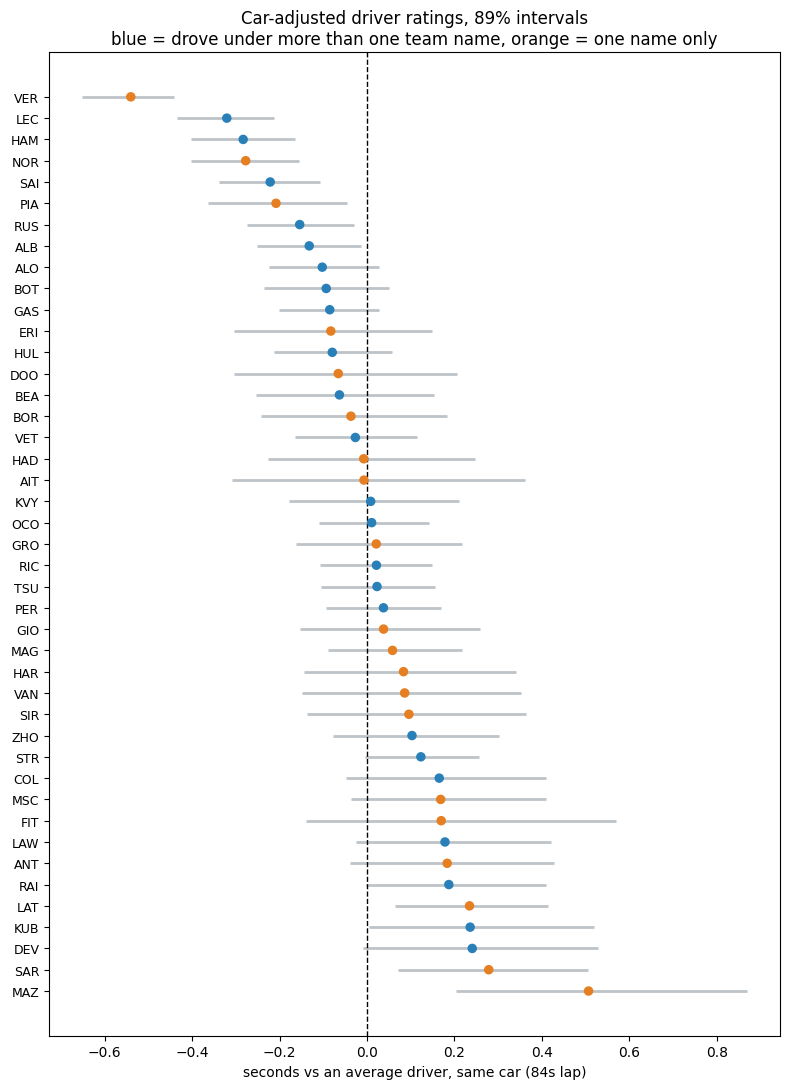

In [85]:
ranked = ratings.sort_values('seconds')
switched = ranked['teams'] > 1

fig, ax = plt.subplots(figsize=(8, 11))
ax.hlines(range(len(ranked)), ranked['lower_89'], ranked['upper_89'],
          color='#bdc3c7', lw=2, zorder=1)
ax.scatter(ranked['seconds'], range(len(ranked)),
           c=np.where(switched, '#2980b9', '#e67e22'), s=34, zorder=3)
ax.axvline(0, color='k', lw=1, ls='--')
ax.set_yticks(range(len(ranked)))
ax.set_yticklabels(ranked.index, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel(f'seconds vs an average driver, same car ({LAP_SECONDS:.0f}s lap)')
ax.set_title('Car-adjusted driver ratings, 89% intervals\n'
             'blue = drove under more than one team name, orange = one name only')
plt.tight_layout()
plt.show()

### What the ranking says

**The order matches what people who follow the sport would say, and the model was told none of it.**
Verstappen sits clear at the top, 0.22s ahead of second place. Leclerc, Hamilton and Norris form the
next group. At the other end sit Mazepin, Sargeant, de Vries and Latifi, the drivers most often named
as the weakest of the period.

That agreement is reassuring rather than impressive. A method that put Mazepin ahead of Verstappen
would be obviously broken, so this is a floor to clear, not an achievement.

**Two results in the middle are worth naming rather than hiding.** Räikkönen comes out at +0.187,
slower than his teammate Giovinazzi at +0.038. And Ericsson at −0.083 sits ahead of both Hülkenberg at
−0.079 and Vettel at −0.026, on 17 sessions against 96 and 87.

**Neither is the model making a claim.** Räikkönen's range is [−0.002, 0.409] and Giovinazzi's is
[−0.153, 0.259]. They overlap along most of their length, so the model is saying it cannot separate
them, which is right for two drivers closely matched in qualifying in their last seasons together.
Ericsson, Hülkenberg and Vettel are spread across 0.057s with ranges five to eight times that wide,
and Ericsson's is 0.452s, more than twice Verstappen's, because 17 sessions buy little.

**So read the ends of this table, not the middle.** Verstappen to Mazepin is a gap far larger than any
range on the grid. Between neighbours in the middle it is far smaller, and their order carries almost
no information.

**A correction to something claimed earlier in this project.** I wrote that drivers who only ever
raced for one team contribute nothing towards separating driver from car. There are 20 of them by team
name, and 22 by constructor once the renames further down this notebook are counted. Verstappen does
not fit that: his `teams` count is 1, within this dataset's 2018 start, and he has the narrowest range
on the grid.

**Changing teams is not the only route. Teammates arriving and leaving does the same job.** Verstappen
stayed at Red Bull and shared the garage with Ricciardo, Gasly, Albon, Pérez, Lawson and Tsunoda,
every one of whom drove for somebody else at some point, so each is a link from Verstappen out to the
rest of the field.

## What makes some ratings more certain than others

If that is the mechanism, how wide a driver's range is should track **how much comparison was
available**: sessions run and number of different teammates, rather than team changes.

In [86]:
teammates = (model_data.merge(model_data, on=['season', 'gp', 'team'])
             .query('drv_x != drv_y')
             .groupby('drv_x')['drv_y'].nunique())

check = ratings.copy()
check['teammates'] = teammates.reindex(check.index).fillna(0)

print('what predicts a narrow interval?')
for col in ['sessions', 'teams', 'teammates']:
    print(f'  correlation(width, {col:10s}) = {check["width"].corr(check[col]):+.2f}')
print()
print('narrowest five:')
print(check.nsmallest(5, 'width')[['seconds', 'width', 'sessions', 'teams', 'teammates']].round(3))
print()
print('widest five:')
print(check.nlargest(5, 'width')[['seconds', 'width', 'sessions', 'teams', 'teammates']].round(3))

what predicts a narrow interval?
  correlation(width, sessions  ) = -0.90
  correlation(width, teams     ) = -0.56
  correlation(width, teammates ) = -0.77

narrowest five:
     seconds  width  sessions  teams  teammates
VER   -0.540  0.211       150      1          6
LEC   -0.321  0.224       154      2          5
GAS   -0.085  0.228       154      4          7
SAI   -0.221  0.229       150      4          4
HAM   -0.283  0.236       150      2          3

widest five:
     seconds  width  sessions  teams  teammates
FIT    0.170  0.709         2      1          1
AIT   -0.007  0.671         1      1          1
MAZ    0.507  0.664        21      1          1
DEV    0.241  0.538        10      2          2
KUB    0.236  0.515        15      2          2


### Precision comes from running a lot and being well connected, not from switching teams

| what predicts a narrow range | correlation |
|---|---|
| sessions | **−0.90** |
| distinct teammates | −0.77 |
| team changes | −0.56 |

A correlation of −0.90 means the more sessions a driver ran, the narrower his range, almost without
exception. Sessions dominate, different teammates come second, and changing constructor, the thing I
had assumed was the key, comes last.

These are three separate correlations rather than one comparison holding the others fixed, and the
three predictors move together: a driver with many sessions has usually had more teammates and more
teams as well. So this ranks them, it does not isolate them.

One caveat on the third row: `teams` counts distinct team **names**, which the section on the
held-back test shows is not the same as counting constructors. Kvyat and Zhou are counted as movers
here on the strength of a rename alone. Correcting it moves 23 movers to 21 and would not reorder the
three rows, but the number is a name count and should be read as one.

**Verstappen** ran 150 sessions and had six different teammates without ever leaving Red Bull, and is
the most precisely rated driver in the data. **Mazepin** ran 21 sessions, a full season's worth, but
had one teammate and one team, so he stays among the least precisely rated.

**So the limitation is narrower than what notebook 01 claimed.** It is not that drivers who stayed at
one team cannot be rated. It is that **drivers with few sessions, or few different teammates, are
weakly connected to the rest of the grid, and their wide ranges show it.**

## Car ratings

**Which cars were quickest over one lap?**

The same treatment applied to each team in each season. This is the side of the question a teammate
comparison can never answer, because teammates share a car: comparing Hamilton with Bottas says
nothing about how good the Mercedes was.

In [87]:
car_seconds = effects_in_seconds(car_draws)

cars = pd.DataFrame({
    'seconds': np.median(car_seconds, axis=0),
    'lower_89': np.percentile(car_seconds, 5.5, axis=0),
    'upper_89': np.percentile(car_seconds, 94.5, axis=0),
}, index=car_names).sort_values('seconds')

print(f'Ten fastest cars, 2018-2025 (seconds vs an average car, {LAP_SECONDS:.0f}s lap):')
print(cars.head(10).round(3))
print()
print('Ten slowest:')
print(cars.tail(10).round(3))

Ten fastest cars, 2018-2025 (seconds vs an average car, 84s lap):
                      seconds  lower_89  upper_89
Mercedes 2020          -0.715    -0.848    -0.585
Ferrari 2018           -0.614    -0.757    -0.471
Mercedes 2021          -0.556    -0.699    -0.410
Ferrari 2019           -0.544    -0.694    -0.392
Mercedes 2018          -0.523    -0.677    -0.358
McLaren 2025           -0.502    -0.659    -0.310
Mercedes 2019          -0.481    -0.639    -0.315
Ferrari 2022           -0.453    -0.614    -0.296
Red Bull Racing 2022   -0.408    -0.574    -0.247
Mercedes 2025          -0.402    -0.574    -0.185

Ten slowest:
                        seconds  lower_89  upper_89
Aston Martin 2022         0.403     0.148     0.651
McLaren 2018              0.412     0.141     0.710
Sauber 2018               0.543     0.253     0.849
Haas F1 Team 2020         0.552     0.252     0.869
Alfa Romeo Racing 2020    0.555     0.244     0.901
Williams 2020             0.625     0.324     0.930
Willia

### The cars match the historical record

None of what follows was given to the model. It saw lap times and nothing else.

**Mercedes 2020 comes out fastest.** The W11 is widely regarded as the most dominant car of the modern
era. **Ferrari 2018 is second and Ferrari 2019 fourth**, with Mercedes 2021 between them. The 2019 car
was a low-drag, high-power package at its strongest over a single lap, which is what a model built on
Q1 pace should pick up.

**One entry does not match the record.** Ferrari 2018 ranks above Mercedes 2018, which took roughly
twice as many poles that year and won both championships. Over a single lap Mercedes was the better
car, and the model says otherwise. That is the distortion this notebook returns to at the end: the
team with the most to hold back in Q1 is the one whose rating suffers most, showing up here in a table
being used as validation.

**At the bottom, Williams 2019 sits at +1.569s, seven tenths of a second slower than the next-worst
car in the dataset.** The FW42 turned up two and a half days late to the first pre-season test and was
widely called one of the worst cars in decades. **Haas 2021**, which abandoned in-season development
to concentrate on the following year's car, is second from bottom.

**Red Bull 2023 is not in the top ten, despite winning 21 of the 22 races that season.** That is a
problem rather than a curiosity, and the notebook comes back to it twice. When a driver is dominant
and rarely beaten by his teammate, the model has little to work with in saying how much of that was
him and how much was the car.

In [88]:
red_bull = cars[cars.index.str.startswith('Red Bull')]
print('Red Bull by season:')
print(red_bull.sort_index().round(3))
print()
print('rank of each (1 = fastest of', len(cars), 'cars):')
for name in red_bull.sort_index().index:
    print(f'  {name:24s} {list(cars.index).index(name) + 1}')

Red Bull by season:
                      seconds  lower_89  upper_89
Red Bull Racing 2018   -0.235    -0.422    -0.043
Red Bull Racing 2019   -0.081    -0.280     0.128
Red Bull Racing 2020    0.031    -0.184     0.256
Red Bull Racing 2021   -0.365    -0.525    -0.199
Red Bull Racing 2022   -0.408    -0.574    -0.247
Red Bull Racing 2023   -0.370    -0.528    -0.186
Red Bull Racing 2024   -0.372    -0.539    -0.166
Red Bull Racing 2025   -0.100    -0.290     0.135

rank of each (1 = fastest of 81 cars):
  Red Bull Racing 2018     16
  Red Bull Racing 2019     27
  Red Bull Racing 2020     41
  Red Bull Racing 2021     13
  Red Bull Racing 2022     9
  Red Bull Racing 2023     12
  Red Bull Racing 2024     11
  Red Bull Racing 2025     26


## Checking the ratings against championship results

**Comparing the top and bottom of the list with famous cars is a weak test.** It shows the extremes
look right, says nothing about whether the middle of the table is sensible, and rests on my own memory
of those seasons.

**A stronger test uses something the model never saw: constructors' championship points.** If the car
ratings measure car performance, they should track how many points each team scored that year. Points
are scored in races, not in qualifying, and appear nowhere in the data the model was fitted to.

I expected the same test on drivers to come out much weaker, since a driver's points depend heavily on
his car and the ratings have the car stripped out. That expectation was wrong.

In [89]:
import io
import zipfile
import requests

archive = requests.get(
    'https://raw.githubusercontent.com/TracingInsights/RaceData/main/data.zip', timeout=60
)
with zipfile.ZipFile(io.BytesIO(archive.content)) as z:
    races = pd.read_csv(z.open('races.csv'))
    constructor_standings = pd.read_csv(z.open('constructor_standings.csv'))
    constructors = pd.read_csv(z.open('constructors.csv'))
    results = pd.read_csv(z.open('results.csv'))
    drivers_table = pd.read_csv(z.open('drivers.csv'))

modern_races = races[races['year'].between(2018, 2025)]
races_per_season = modern_races.groupby('year').size()
season_finale = modern_races.sort_values('round').groupby('year').tail(1)[['raceId', 'year']]


# teams that were renamed between the two sources
ALIASES = {
    'kick sauber': 'sauber',
    'racing bulls': 'rb',
    'alphatauri': 'alphatauri',
}


def normalise(name):
    """Team names differ between sources: 'Red Bull Racing' vs 'Red Bull'."""
    cleaned = name.lower()
    for suffix in [' f1 team', ' racing', ' team']:
        if cleaned.endswith(suffix):
            cleaned = cleaned[: -len(suffix)]
    cleaned = cleaned.strip()
    return ALIASES.get(cleaned, cleaned)


# points per race, because the calendar ran 17 races in 2020 and 24 in 2024
constructor_points = (
    constructor_standings.merge(season_finale, on='raceId')
    .merge(constructors[['constructorId', 'name']], on='constructorId')
    .assign(key=lambda d: d['name'].map(normalise))
    .assign(points_per_race=lambda d: d['points'] / d['year'].map(races_per_season))
    [['year', 'key', 'points', 'points_per_race']]
)
print('constructor-seasons with points:', len(constructor_points))
print(f'races per season: {races_per_season.min()} to {races_per_season.max()}')

constructor-seasons with points: 80
races per season: 17 to 24


In [90]:
car_ratings = cars.reset_index()
car_ratings = car_ratings.rename(columns={car_ratings.columns[0]: 'label'})
car_ratings['year'] = car_ratings['label'].str[-4:].astype(int)
car_ratings['key'] = car_ratings['label'].str[:-5].map(normalise)

merged_cars = car_ratings.merge(constructor_points, on=['year', 'key'], how='left')

unmatched = merged_cars[merged_cars['points_per_race'].isna()]['label'].tolist()
print('car-seasons matched to points:',
      merged_cars['points_per_race'].notna().sum(), 'of', len(merged_cars))
print('unmatched:', unmatched or 'none')

car-seasons matched to points: 80 of 81
unmatched: ['Racing Point 2018']


In [91]:
from scipy.stats import spearmanr

matched = merged_cars.dropna(subset=['points_per_race'])

# ratings are in seconds off average, so lower is faster: expect a negative correlation
car_r = spearmanr(matched['seconds'], matched['points_per_race'])
print(f'car rating vs constructor points per race : rho = {car_r.statistic:+.3f}'
      f'  (p = {car_r.pvalue:.2g}, n = {len(matched)})')

# drivers: points per race entered, so a long career is not mistaken for skill
driver_points = (
    results.merge(modern_races[['raceId', 'year']], on='raceId')
    .merge(drivers_table[['driverId', 'code']], on='driverId')
    .groupby('code')
    .agg(points=('points', 'sum'), races=('raceId', 'nunique'))
)
driver_points['points_per_race'] = driver_points['points'] / driver_points['races']

driver_check = (ratings.join(driver_points)
                .dropna(subset=['points_per_race'])
                .query('races >= 20'))
driver_r = spearmanr(driver_check['seconds'], driver_check['points_per_race'])
print(f'driver rating vs driver points per race   : rho = {driver_r.statistic:+.3f}'
      f'  (p = {driver_r.pvalue:.2g}, n = {len(driver_check)})')

car rating vs constructor points per race : rho = -0.797  (p = 1e-18, n = 80)
driver rating vs driver points per race   : rho = -0.749  (p = 4.2e-08, n = 39)


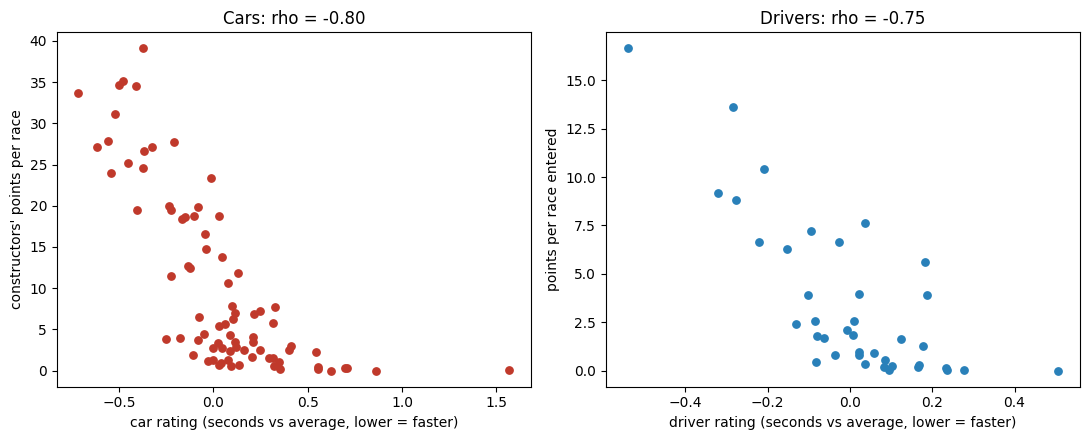

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(matched['seconds'], matched['points_per_race'], s=28, c='#c0392b')
axes[0].set_xlabel('car rating (seconds vs average, lower = faster)')
axes[0].set_ylabel("constructors' points per race")
axes[0].set_title(f'Cars: rho = {car_r.statistic:+.2f}')

axes[1].scatter(driver_check['seconds'], driver_check['points_per_race'], s=28, c='#2980b9')
axes[1].set_xlabel('driver rating (seconds vs average, lower = faster)')
axes[1].set_ylabel('points per race entered')
axes[1].set_title(f'Drivers: rho = {driver_r.statistic:+.2f}')

plt.tight_layout()
plt.show()

### The driver version of that test does not work, and the reason is worth spelling out

**The car ratings track constructors' points at rho = -0.80.** Rho is a rank correlation: −1 would
mean the fastest-rated car scored the most points, the second-fastest the second most, and so on down
the order. −0.80 is close to that. The ratings were built from Q1 lap times and know nothing about
race results, so this is what a validation check should look like.

**I expected the driver correlation to be far weaker. It is -0.75, almost as strong, and my reasoning
was wrong.** Points do depend heavily on the car. But **good drivers are hired by good teams**, so a
driver rating will track points whether or not the model has separated the two. This test cannot tell
me which of those happened.

**The test that does work compares teammates.** Two drivers in the same car in the same season have
the car held constant: Hamilton and Bottas drove the same Mercedes. If the ratings carry real
information about drivers, the better-rated one should usually score more points than his teammate.

In [93]:
from scipy.stats import binomtest

season_driver_points = (
    results.merge(modern_races[['raceId', 'year']], on='raceId')
    .merge(drivers_table[['driverId', 'code']], on='driverId')
    .groupby(['year', 'constructorId', 'code'])['points'].sum()
    .reset_index()
)

pairs = (season_driver_points.merge(ratings[['seconds']], left_on='code', right_index=True)
         .groupby(['year', 'constructorId'])
         .filter(lambda g: len(g) == 2))

# The same two drivers share a garage for several seasons, so seasons are not
# independent trials. Record the pairing alongside each season's outcome.
by_pairing = {}
for _, garage in pairs.groupby(['year', 'constructorId']):
    faster = garage.loc[garage['seconds'].idxmin()]
    slower = garage.loc[garage['seconds'].idxmax()]
    if faster['points'] == slower['points']:
        continue
    key = tuple(sorted([faster['code'], slower['code']]))
    by_pairing.setdefault(key, []).append(faster['points'] > slower['points'])

seasons = [outcome for outcomes in by_pairing.values() for outcome in outcomes]
votes = [sum(o) > len(o) / 2 for o in by_pairing.values() if sum(o) * 2 != len(o)]

for label, trials in [('seasons', seasons), ('pairings', votes)]:
    wins = sum(trials)
    test = binomtest(wins, len(trials), 0.5, alternative='greater')
    print(f'{label:9s} as trials: better-rated driver ahead in {wins} of {len(trials)} '
          f'({wins / len(trials):.1%}), p = {test.pvalue:.4f}')
print('  pairings is the defensible one: the same garage recurs across seasons')

seasons   as trials: better-rated driver ahead in 42 of 60 (70.0%), p = 0.0013
pairings  as trials: better-rated driver ahead in 26 of 38 (68.4%), p = 0.0168
  pairings is the defensible one: the same garage recurs across seasons


**The better-rated driver out-scored his teammate in 42 of 60 seasons, 70%**, against the 50% a coin
flip would give. Those 60 seasons are not 60 independent results: the same two drivers often share a
garage for years, so a pairing that agrees four years running is closer to one verdict than four.
Collapsing each pairing to a single verdict gives **26 of 38, 68.4% (p = 0.017)**, and that is the
figure to quote.

**Both counts include only the cases that produced a verdict.** Seasons where the two drivers finished
level on points are dropped, and so are pairings that split evenly across the seasons they shared. An
even split is evidence against the ratings, so removing it makes 68.4% the optimistic reading, and the
number of cases dropped at each stage is not reported.

The car is held constant inside every one of those comparisons, which the points correlation could not
do. So the driver ratings carry information about drivers specifically, not about the car they
happened to be sitting in.

**The 30% that go the other way are expected rather than a problem.** A season's points depend on
reliability, crashes, strategy calls and which driver got the new floor first. The ratings describe
one thing only: pace over a single qualifying lap. A rating built from Q1 times should not predict a
full championship perfectly, and one that did would be suspicious.

**Two further limitations on this test.** The 60 comparisons are far fewer than the 3,008
driver-sessions behind the ratings, because only team-seasons with exactly two rated drivers can be
used. And each driver carries one career-long rating while the points are per season, so a driver who
improved substantially over eight years is judged against all his teammates on a single career
average.

One car-season, Racing Point 2018, could not be matched to a points total. The team was renamed
mid-season, so the two sources disagree about what to call it. It is left unmatched rather than
patched by hand.

## Did the car matter more in some seasons than in others?

**The headline, 2.8 times, is one number covering eight seasons at once.** That assumes the balance
between driver and car sat still from 2018 to 2025, a strong assumption for a sport that brought in a
budget cap in 2021 and rewrote its aerodynamic rules in 2022.

**The fitted model already contains most of the answer, with no refitting needed.** Every team has its
own effect in every season, so how spread out those effects are within one season is that season's
range of car performance. Comparing it with how spread out the drivers are gives a per-season version
of the headline ratio.

**One caveat first, because it limits what the result can prove.** The model estimates a
single figure for how spread out team-season effects are in general, and every individual season is
pulled towards it, so real differences between seasons look smaller here than they are. This check can
suggest the balance moved. It cannot measure by how much.

In [94]:
car_labels = posterior['1|team_season'].coords['team_season__factor_dim'].values
car_seasons = np.array([int(label[-4:]) for label in car_labels])

# ddof=1: the seasons hold ~10 cars against 43 drivers, so the population formula
# would bias the two spreads by different amounts
driver_spread = driver_draws.std(axis=1, ddof=1)


def robust_spread(effects):
    """Interquartile range, which one extreme car cannot move."""
    return (np.percentile(effects, 75, axis=1) - np.percentile(effects, 25, axis=1))


per_season = []
for season in np.unique(car_seasons):
    in_season = car_draws[:, car_seasons == season]
    by_sd = in_season.std(axis=1, ddof=1)
    by_iqr = robust_spread(in_season)
    ratio = by_sd / driver_spread
    per_season.append({
        'season': season,
        'teams': in_season.shape[1],
        'car_sd': np.median(by_sd),
        'car_iqr': np.median(by_iqr),
        'car_vs_driver': np.median(ratio),
        'lower_89': np.percentile(ratio, 5.5),
        'upper_89': np.percentile(ratio, 94.5),
        'variance_ratio': np.median(ratio ** 2),
        # is the spread being set by one car?
        'iqr_over_sd': np.median(by_iqr / by_sd),
    })

era = pd.DataFrame(per_season).set_index('season')
era.round(3)

,teams,car_sd,car_iqr,car_vs_driver,lower_89,upper_89,variance_ratio,iqr_over_sd
season,,,,,,,,
2018,11,0.273,0.312,2.051,1.663,2.516,4.209,1.146
2019,10,0.302,0.181,2.266,1.809,2.843,5.137,0.599
2020,10,0.277,0.231,2.072,1.649,2.623,4.294,0.837
2021,10,0.239,0.223,1.799,1.320,2.399,3.238,0.929
2022,10,0.216,0.185,1.625,1.278,2.064,2.642,0.858
2023,10,0.111,0.124,0.835,0.587,1.132,0.698,1.128
2024,10,0.147,0.182,1.100,0.799,1.473,1.211,1.262
2025,10,0.153,0.166,1.148,0.861,1.490,1.319,1.100


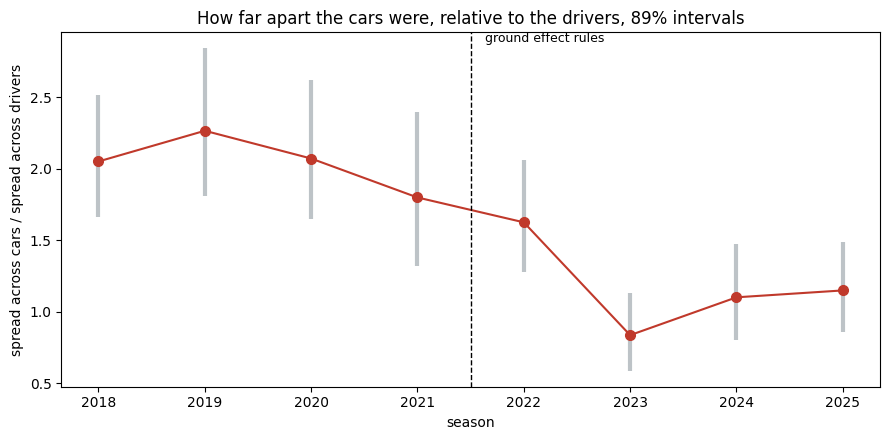

In [95]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.vlines(era.index, era['lower_89'], era['upper_89'], color='#bdc3c7', lw=3)
ax.plot(era.index, era['car_vs_driver'], 'o-', color='#c0392b', lw=1.5, ms=7)
ax.axvline(2021.5, color='k', ls='--', lw=1)
ax.text(2021.6, ax.get_ylim()[1], ' ground effect rules', va='top', fontsize=9)
ax.set_xlabel('season')
ax.set_ylabel('spread across cars / spread across drivers')
ax.set_title('How far apart the cars were, relative to the drivers, 89% intervals')
plt.tight_layout()
plt.show()

### What it looks like at first

| season | cars vs drivers (spread) | squared |
|---|---|---|
| 2018 | 2.05 | 4.2 |
| 2019 | **2.27** | **5.1** |
| 2020 | 2.07 | 4.3 |
| 2021 | 1.80 | 3.2 |
| 2022 | 1.63 | 2.6 |
| 2023 | **0.84** | **0.7** |
| 2024 | 1.10 | 1.2 |
| 2025 | 1.15 | 1.3 |

Read straight off, this says the car's advantage over the driver collapsed by a factor of seven
between 2019 and 2023, with the timing lining up against the 2021 budget cap and the 2022 rule change.
The next section is where it falls apart.

### Is that trend real, or is it one Williams?

**A fall from 5.1 to 0.7 rests on a spread measured across about ten cars a season**, and a standard
deviation is easily dragged by one extreme value. Williams 2019 sits at +1.569s, seven tenths clear of
the next-slowest car in eight years, inside 2019's ten-car sample. The 2023 dip falls where
sandbagging should be worst, since that was the most dominant season in the data and dominant teams
hold back most in Q1.

Three checks: drop each season's slowest car, swap to a spread measure the extremes cannot move, and
compare against constructors' championship points, which come from races where nobody sandbags.

In [96]:
# what happens to each season once its slowest car is removed
trimmed = []
for season in np.unique(car_seasons):
    in_season = car_draws[:, car_seasons == season]
    slowest = np.argmax(np.median(in_season, axis=0))
    without = np.delete(in_season, slowest, axis=1)
    trimmed.append({
        'season': season,
        'slowest car': car_labels[car_seasons == season][slowest],
        'car_sd': np.median(in_season.std(axis=1, ddof=1)),
        'car_sd_trimmed': np.median(without.std(axis=1, ddof=1)),
        'ratio_full': np.median(in_season.std(axis=1, ddof=1) / driver_spread),
        'ratio_trimmed': np.median(without.std(axis=1, ddof=1) / driver_spread),
    })

pd.DataFrame(trimmed).set_index('season').round(3)

,slowest car,car_sd,car_sd_trimmed,ratio_full,ratio_trimmed
season,,,,,
2018,Williams 2018,0.273,0.262,2.051,1.970
2019,Williams 2019,0.302,0.207,2.266,1.551
2020,Williams 2020,0.277,0.276,2.072,2.064
2021,Haas F1 Team 2021,0.239,0.201,1.799,1.511
2022,Williams 2022,0.216,0.201,1.625,1.508
2023,Alfa Romeo 2023,0.111,0.108,0.835,0.810
2024,Kick Sauber 2024,0.147,0.122,1.100,0.914
2025,Kick Sauber 2025,0.153,0.151,1.148,1.132


In [97]:
# an outside check: how spread out were the constructors' championship points?
points_spread = (constructor_points.groupby('year')['points_per_race']
                 .agg(points_sd=lambda s: s.std(ddof=1),
                      points_iqr=lambda s: s.quantile(.75) - s.quantile(.25),
                      teams='size'))

outside = era[['car_sd', 'car_iqr', 'car_vs_driver']].join(points_spread)
print(outside.round(3).to_string())
print()

# four combinations, because the choice of spread measure is exactly what is in question
print('car spread vs points spread, all four combinations:')
for car_col in ['car_sd', 'car_iqr']:
    for points_col in ['points_sd', 'points_iqr']:
        matched = outside.dropna(subset=[points_col])
        rho = spearmanr(matched[car_col], matched[points_col])
        print(f'  {car_col:8s} vs {points_col:11s}: rho = {rho.statistic:+.3f}  '
              f'(p = {rho.pvalue:.3f}, n = {len(matched)})')
print()
print('trend with season (the "did anything change over time" question):')
for col in ['car_sd', 'car_iqr', 'points_sd', 'points_iqr']:
    matched = outside.dropna(subset=[col])
    rho = spearmanr(matched.index, matched[col])
    print(f'  {col:11s} vs season: rho = {rho.statistic:+.3f}  (p = {rho.pvalue:.3f})')

        car_sd  car_iqr  car_vs_driver  points_sd  points_iqr  teams
season                                                              
2018     0.273    0.312          2.051     11.653      14.083     10
2019     0.302    0.181          2.266     11.899      13.714     10
2020     0.277    0.231          2.072     10.280       9.853     10
2021     0.239    0.223          1.799     10.309      12.494     10
2022     0.216    0.185          1.625     12.308      17.636     10
2023     0.111    0.124          0.835     12.247      16.102     10
2024     0.147    0.182          1.100     11.999      21.240     10
2025     0.153    0.166          1.148     10.984      14.844     10

car spread vs points spread, all four combinations:
  car_sd   vs points_sd  : rho = -0.500  (p = 0.207, n = 8)
  car_sd   vs points_iqr : rho = -0.762  (p = 0.028, n = 8)
  car_iqr  vs points_sd  : rho = -0.452  (p = 0.260, n = 8)
  car_iqr  vs points_iqr : rho = -0.452  (p = 0.260, n = 8)

trend with seaso

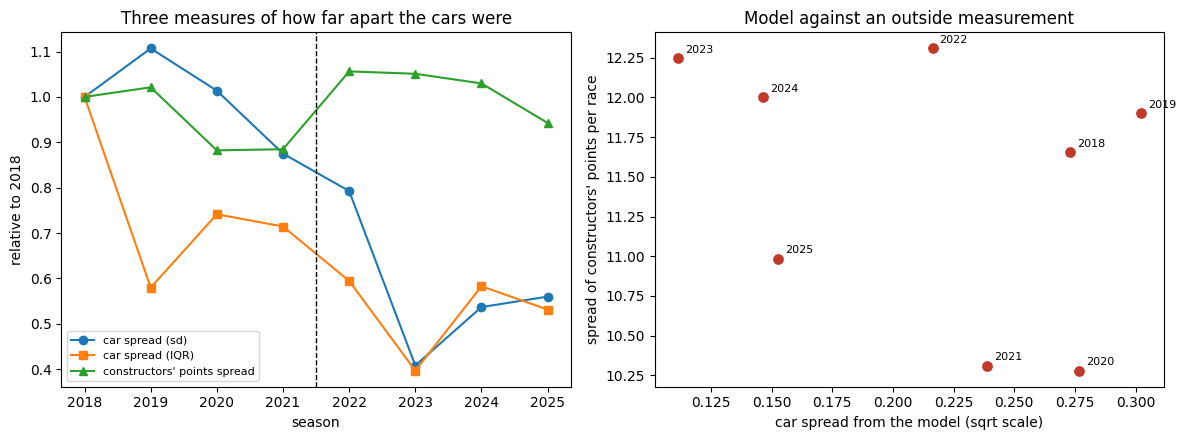

In [98]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(era.index, era['car_sd'] / era['car_sd'].iloc[0], 'o-', label='car spread (sd)')
axes[0].plot(era.index, era['car_iqr'] / era['car_iqr'].iloc[0], 's-', label='car spread (IQR)')
axes[0].plot(outside.index, outside['points_sd'] / outside['points_sd'].iloc[0], '^-',
             label="constructors' points spread")
axes[0].axvline(2021.5, color='k', ls='--', lw=1)
axes[0].set_ylabel('relative to 2018')
axes[0].set_xlabel('season')
axes[0].set_title('Three measures of how far apart the cars were')
axes[0].legend(fontsize=8)

axes[1].scatter(outside['car_sd'], outside['points_sd'], s=45, c='#c0392b')
for season, row in outside.dropna(subset=['points_sd']).iterrows():
    axes[1].annotate(str(season), (row['car_sd'], row['points_sd']),
                     textcoords='offset points', xytext=(5, 4), fontsize=8)
axes[1].set_xlabel('car spread from the model (sqrt scale)')
axes[1].set_ylabel("spread of constructors' points per race")
axes[1].set_title('Model against an outside measurement')

plt.tight_layout()
plt.show()

### The trend does not survive any of the three checks

**One car was carrying 2019.** Removing each season's slowest car moves 2019 from 2.27 to **1.55**, a
32% fall, while 2023 goes 0.84 to 0.81 and barely moves. That car is Williams 2019.

**Under a measure the extremes cannot move, the trend mostly disappears.** Swapping the standard
deviation for the interquartile range weakens the correlation with season from **−0.83 to −0.67**, and
2019 comes out *lower* than 2022.

**The outside check does not support it either.** If the field had converged, constructors'
championship points should have converged too, and points come from races where nobody holds back.
They did not: the points spread trends the other way. Correlating it against the model's per-season
spread gives rho = **−0.762** (p = 0.028) on eight seasons, the strongest of the four combinations of
spread measure the cell computes. The other three run from −0.45 to −0.50 with p between 0.21 and
0.26. All four are negative, which is the part worth keeping; no single one of them is a number to
lean on.

**So the claim is withdrawn.** Per-season car spread from Q1 pace does not measure how competitive the
field was.

**The failure is worth more than the finding would have been.** Sandbagging is worst when one team
dominates, so the seasons with the biggest real gaps show the *smallest* measured Q1 spread, which is
the backwards relationship observed. It is not independent evidence: it is the same mechanism
described under "Where the method breaks down", showing up somewhere else.

It also sharpens what the car ratings are for. Ranking cars **within** a season holds up, since the
ratings track points at rho = −0.797 across 80 team-seasons. Comparing the **spread** between seasons
does not, because how much the leader holds back changes from year to year.

## The one test the model could actually fail

**Everything checked so far compares the ratings with things that already happened**: championship
points, teammate records, and in notebook 05 a second ranking method. None of it can catch the model
being wrong in a way that still fits the data it was given.

**The model claims something stronger than a good description.** It says qualifying pace is a driver
effect plus a car effect. If that is true, then for a driver and a car that **never appeared
together**, adding that driver's number to that car's number should predict the pace the pairing
actually produced.

**That is a real prediction, and it can come out wrong.** Driver skill might not transfer between
cars. If it does not, the two parts do not add up, the split is measuring something narrower than it
claims, and the 2.8 times headline does not mean what it appears to mean.

**The test hides a driver-team pairing from the model entirely**, while keeping that driver at his
**other** teams, so his skill is still measured, and his **teammate** in that same car, so the car is
still measured. The model then predicts a combination it has never seen, and the real answer is
already in the data.

First, how many pairings could support this, and how much data hiding them would cost.

In [99]:
pairings = (model_data.groupby(['drv', 'team'])
            .agg(sessions=('drv', 'size'), seasons=('season', 'nunique'))
            .reset_index())

teams_per_driver = pairings.groupby('drv')['team'].nunique()
drivers_per_team = pairings.groupby('team')['drv'].nunique()

# a pairing can be held out only if the driver is identified elsewhere
# and the car is still identified by someone else
eligible = pairings[
    pairings['drv'].map(teams_per_driver).gt(1)
    & pairings['team'].map(drivers_per_team).gt(1)
].sort_values('sessions', ascending=False)

print(f'driver-team pairings in total : {len(pairings)}')
print(f'eligible to hold out          : {len(eligible)}')
print(f'sessions they cover           : {eligible["sessions"].sum()} '
      f'of {len(model_data)} ({eligible["sessions"].sum() / len(model_data):.0%})')
print()
print('sessions per eligible pairing:')
print(eligible['sessions'].describe().round(1).to_string())
print()
print(eligible.head(12).to_string(index=False))

driver-team pairings in total : 87
eligible to hold out          : 67
sessions they cover           : 2165 of 3008 (72%)

sessions per eligible pairing:
count     67.0
mean      32.3
std       30.4
min        1.0
25%       13.5
50%       22.0
75%       44.0
max      138.0

drv            team  sessions  seasons
LEC         Ferrari       138        7
HAM        Mercedes       126        7
STR    Aston Martin       102        5
RUS        Mercedes        85        5
ALB        Williams        82        4
OCO          Alpine        81        4
SAI         Ferrari        81        4
PER Red Bull Racing        80        4
BOT        Mercedes        67        4
TSU      AlphaTauri        62        3
ALO    Aston Martin        62        3
GAS      AlphaTauri        61        3


Hiding all 67 usable pairings would remove 72% of the data, which would destroy the effects the test
is meant to check. Only a subset can be hidden, chosen by a rule rather than by picking whichever
names look interesting.

Three constraints, each with a reason:

- **Between 20 and 90 sessions per pairing.** Below 20, the pairing's real pace is itself measured too
  noisily to serve as an answer key. Above 90, hiding it removes most of a driver's career, which
  weakens the driver rating the test depends on.
- **At most one pairing per driver**, so each hidden driver is still rated from his remaining teams.
- **At most one pairing per team.** Teams run two cars, so removing one driver leaves his teammate
  behind to measure the car. Removing both would delete that team-season entirely.

Together these cap the hidden set at roughly one pairing per team, aiming at about 15% of all
sessions.

In [100]:
HOLDOUT_SHARE = 0.15

if 'team_season' not in model_data.columns:
    model_data['team_season'] = model_data['team'] + ' ' + model_data['season'].astype(str)

candidates = (eligible[eligible['sessions'].between(20, 90)]
              .sort_values(['drv', 'team'])
              .reset_index(drop=True))

order = np.random.default_rng(0).permutation(len(candidates))
budget = HOLDOUT_SHARE * len(model_data)

chosen, used_drivers, used_teams, held = [], set(), set(), 0
for position in order:
    pairing = candidates.loc[position]
    if pairing['drv'] in used_drivers or pairing['team'] in used_teams:
        continue
    if held + pairing['sessions'] > budget:
        continue
    chosen.append(pairing)
    used_drivers.add(pairing['drv'])
    used_teams.add(pairing['team'])
    held += pairing['sessions']

holdout = pd.DataFrame(chosen).reset_index(drop=True)

is_held = pd.Series(False, index=model_data.index)
for _, pairing in holdout.iterrows():
    is_held |= (model_data['drv'] == pairing['drv']) & (model_data['team'] == pairing['team'])

train_rows = model_data[~is_held]
held_rows = model_data[is_held]

print(f'pairings held out : {len(holdout)}')
print(f'sessions held out : {len(held_rows)} of {len(model_data)} '
      f'({len(held_rows) / len(model_data):.0%})')
print()
print('identification checks:')
print('  every held-out driver still appears in training     :',
      held_rows['drv'].isin(train_rows['drv']).all())
print('  every held-out team-season still appears in training:',
      held_rows['team_season'].isin(train_rows['team_season']).all())
print()
print(holdout[['drv', 'team', 'sessions', 'seasons']].to_string(index=False))

pairings held out : 10
sessions held out : 451 of 3008 (15%)

identification checks:
  every held-out driver still appears in training     : True
  every held-out team-season still appears in training: True

drv            team  sessions  seasons
ALO          Alpine        44        2
HAM         Ferrari        24        1
RUS        Williams        52        3
HUL    Haas F1 Team        38        2
VET    Aston Martin        42        2
SAI         McLaren        30        2
ZHO      Alfa Romeo        44        2
PER Red Bull Racing        80        4
BOT        Mercedes        67        4
STR    Racing Point        30        2


The model is fitted again from scratch on the reduced data, using the same formula, the same starting
assumptions and the same sampler settings as notebook 02. Only the data changes. Changing anything
else would make it impossible to tell a failed test apart from a difference between two models.

**A note on the diagnostic numbers below.** `az.summary` returns NaN for every parameter of these
fits in the current Kaggle image, so R-hat and effective sample size are computed by hand here.
Convergence is this project's stated success criterion, so reporting it as unavailable was not an
option.

**What they mean.** R-hat asks whether the four independent runs describe the same thing: 1.00 means
yes, and much above 1.01 means they disagree and the answer cannot be trusted. Effective sample size
asks how many independent looks those runs amount to, since each step resembles the one before it.
Divergences are the sampler reporting that it hit ground it could not cross: zero is what you want.

Both calculations are the standard ones, and both are checked two cells below against cases whose
answer is known in advance: independent draws, four chains parked two standard deviations apart, and
a series with a known amount of correlation built into it. A hand-written replacement for a library
function should have to earn its place that way.

In [101]:
!pip install -q bambi

import bambi as bmb

priors_sqrt = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    'sigma': bmb.Prior('HalfNormal', sigma=0.5),
}

def split_rhat(draws):
    """Split R-hat: within-chain against between-chain variance, halves compared."""
    chains, length = draws.shape
    half = length // 2
    pieces = np.concatenate([draws[:, :half], draws[:, half:2 * half]])
    within = pieces.var(axis=1, ddof=1).mean()
    between = half * pieces.mean(axis=1).var(ddof=1)
    return np.sqrt(((half - 1) / half * within + between / half) / within)


def effective_size(draws):
    """ESS from the autocorrelation, truncated by Geyer's initial positive sequence."""
    chains, length = draws.shape
    centred = draws - draws.mean(axis=1, keepdims=True)
    padded = 2 ** int(np.ceil(np.log2(2 * length)))
    spectrum = np.fft.rfft(centred, n=padded, axis=1)
    autocovariance = np.fft.irfft(spectrum * np.conjugate(spectrum), n=padded,
                                  axis=1)[:, :length].real / length
    correlation = autocovariance.mean(axis=0)
    correlation = correlation / correlation[0]
    total = 0.0
    for lag in range(1, length - 1, 2):
        pair = correlation[lag] + correlation[lag + 1]
        if pair < 0:
            break
        total += pair
    return chains * length / (1 + 2 * total)


def report_convergence(label, idata):
    """arviz returns NaN for these fits in the current image, so compute it here.

    Covers the scalar parameters only (the intercept, the residual sd and the group sds),
    not the ~130 individual group-level effects, so 'worst R-hat' is worst among those.
    """
    scalars = [name for name in idata.posterior.data_vars
               if idata.posterior[name].dims == ('chain', 'draw')]
    rhats = {name: split_rhat(idata.posterior[name].values) for name in scalars}
    sizes = {name: effective_size(idata.posterior[name].values) for name in scalars}
    worst = max(rhats, key=rhats.get)
    print(f'{label:22s} divergences {int(idata.sample_stats["diverging"].sum()):3d}  '
          f'worst R-hat {rhats[worst]:.4f} ({worst})  '
          f'lowest ESS {min(sizes.values()):,.0f}')


holdout_model = bmb.Model('sqrt_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)',
                          data=train_rows, priors=priors_sqrt)
holdout_idata = holdout_model.fit(draws=2000, tune=1000, chains=4, random_seed=0,
                                  target_accept=0.99)

report_convergence('broken holdout', holdout_idata)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 89 seconds.


broken holdout         divergences   0  worst R-hat 1.0008 (1|season_sigma)  lowest ESS 1,641


In [102]:
# The two diagnostics above replace az.summary, so they are checked against cases whose answer
# is known in advance.
rng = np.random.default_rng(0)
CHAINS, LENGTH = 4, 2000

independent = rng.standard_normal((CHAINS, LENGTH))
print(f'independent draws        R-hat {split_rhat(independent):.3f}  '
      f'ESS {effective_size(independent):5.0f} of {CHAINS * LENGTH}')

offsets = np.linspace(-2, 2, CHAINS).reshape(CHAINS, 1)
parked = rng.standard_normal((CHAINS, LENGTH)) + offsets
print(f'chains parked 2 sd apart R-hat {split_rhat(parked):.3f}  '
      f'(should be far above 1.01)')

RHO = 0.8
noise = rng.standard_normal((CHAINS, LENGTH))
correlated = np.zeros((CHAINS, LENGTH))
for step in range(1, LENGTH):
    correlated[:, step] = RHO * correlated[:, step - 1] + noise[:, step] * np.sqrt(1 - RHO ** 2)
theoretical = CHAINS * LENGTH * (1 - RHO) / (1 + RHO)
measured = effective_size(correlated)
print(f'AR(1) with rho = {RHO}      ESS {measured:5.0f} against a theoretical {theoretical:.0f}, '
      f'ratio {measured / theoretical:.2f}')


independent draws        R-hat 1.000  ESS  7849 of 8000
chains parked 2 sd apart R-hat 1.887  (should be far above 1.01)
AR(1) with rho = 0.8      ESS   861 against a theoretical 889, ratio 0.97


In [103]:
held_posterior = holdout_idata.posterior


def effect_lookup(term, dim):
    values = held_posterior[term].mean(dim=('chain', 'draw')).values
    labels = [str(label) for label in held_posterior[term].coords[dim].values]
    return dict(zip(labels, values))


baseline_pace = float(held_posterior['Intercept'].mean())
driver_effect = held_rows['drv'].astype(str).map(effect_lookup('1|drv', 'drv__factor_dim'))
car_effect = held_rows['team_season'].astype(str).map(
    effect_lookup('1|team_season', 'team_season__factor_dim'))
season_effect = held_rows['season'].astype(str).map(
    effect_lookup('1|season', 'season__factor_dim'))

actual = held_rows['gap_to_fastest'].to_numpy()
predictors = {
    'season average only': baseline_pace + season_effect,
    'car only': baseline_pace + season_effect + car_effect,
    'driver only': baseline_pace + season_effect + driver_effect,
    'driver + car': baseline_pace + season_effect + car_effect + driver_effect,
}

accuracy = pd.DataFrame([
    {
        'predictor': name,
        'mae': np.abs(np.clip(sqrt_pace, 0, None) ** 2 - actual).mean(),
        'rmse': np.sqrt(((np.clip(sqrt_pace, 0, None) ** 2 - actual) ** 2).mean()),
    }
    for name, sqrt_pace in predictors.items()
]).set_index('predictor')

print(f'predicting {len(held_rows)} driver-sessions the model never saw')
print('all figures are percentage points of gap to the session\'s fastest lap')
print()
accuracy.round(4)

predicting 451 driver-sessions the model never saw
all figures are percentage points of gap to the session's fastest lap



,mae,rmse
predictor,,
season average only,0.5567,0.7492
car only,0.4453,0.6023
driver only,0.6034,0.8340
driver + car,0.4895,0.6868


### The model failed its own test, so the test gets checked first

| predictor | MAE | RMSE |
|---|---|---|
| season average only | 0.5567 | 0.7492 |
| **car only** | **0.4453** | **0.6023** |
| driver only | 0.6034 | 0.8340 |
| driver + car | 0.4895 | 0.6868 |

Both columns are in percentage points of gap to the session's fastest lap, so lower is better. MAE is
the average miss; RMSE punishes big misses more heavily.

**Adding the driver makes the prediction worse.** Knowing only which car someone was in predicts their
pace better than knowing the car and the driver together. Taken at face value, driver and car do not
add up the way the model says, and the whole split would not mean what this project claims.

**A failed test can fail in two ways:** the model's claim is wrong, or the test was never capable of
judging it.

**The sampling is not the explanation.** This fit had no divergences, a worst R-hat of **1.0008** and
a lowest effective sample size of **1,641**, which is cleaner than several fits this project does rely
on. Whatever went wrong is in how the hidden set was chosen, not in the fitting.

**The two rules used were one pairing per driver and one per team**, so every hidden driver kept
another team and every hidden car kept a teammate. Both held. Neither is enough. What lets the model
tell a driver apart from his car is a **chain of comparisons running through the whole grid**: this
driver shared a garage with that driver, who drove for somebody else, whose teammate drove for a third
team, and so on. Removing pairings can cut that chain while leaving every individual driver and car
still present in the data.

In [104]:
def components(rows):
    """Connected pieces of the driver-to-car graph. One piece means everything is
    identified against everything else; more than one means it is not."""
    parent = {}

    def find(node):
        parent.setdefault(node, node)
        while parent[node] != node:
            parent[node] = parent[parent[node]]
            node = parent[node]
        return node

    def union(left, right):
        root_left, root_right = find(left), find(right)
        if root_left != root_right:
            parent[root_left] = root_right

    for driver, car in rows[['drv', 'team_season']].drop_duplicates().itertuples(index=False):
        union(('driver', driver), ('car', car))

    grouped = {}
    for node in list(parent):
        grouped.setdefault(find(node), []).append(node)
    return sorted(grouped.values(), key=len, reverse=True)


def missing_levels(training, held):
    """Levels the prediction needs that the fit would never see.

    Connectivity does not catch these: a driver or car with no training rows is absent
    from the graph rather than disconnected from it.
    """
    return (sorted(set(held['drv']) - set(training['drv'])),
            sorted(set(held['team_season']) - set(training['team_season'])))


pieces = components(train_rows)
print(f'connected pieces in the training data: {len(pieces)}')
for piece in pieces:
    drivers = sorted(name for kind, name in piece if kind == 'driver')
    if len(pieces) > 1 and len(piece) < 40:
        cars = sorted({name.rsplit(' ', 1)[0] for kind, name in piece if kind == 'car'})
        print(f'  isolated piece: drivers {drivers} / cars {cars}')
print()
print('full data, for comparison:', len(components(model_data)), 'piece(s)')

connected pieces in the training data: 4
  isolated piece: drivers ['FIT', 'GRO', 'MAG', 'MAZ', 'MSC'] / cars ['Haas F1 Team']
  isolated piece: drivers ['ANT', 'HAM', 'RUS'] / cars ['Mercedes']
  isolated piece: drivers ['BOT', 'ZHO'] / cars ['Alfa Romeo', 'Kick Sauber']

full data, for comparison: 1 piece(s)


### The chain was cut in three places, and the repair is to check it directly

**The training data falls into four separate pieces where the full data forms one.** Three of them are
sealed off from the rest of the grid:

| isolated piece | drivers | cars |
|---|---|---|
| Mercedes | ANT, HAM, RUS | Mercedes |
| Haas | FIT, GRO, MAG, MAZ, MSC | Haas |
| Sauber | BOT, ZHO | Alfa Romeo, Kick Sauber |

**Mercedes is the clearest case.** Hiding Bottas at Mercedes removed one of its drivers. Hiding
Hamilton at Ferrari and Russell at Williams removed the only other teams those two ever drove for.
What is left is closed: every driver still in a Mercedes drove nothing else, and nobody outside drove
one.

**Inside a closed piece, driver skill and car strength cannot be told apart at all. Only their sum
can.** Nothing in the data says whether the Mercedes was quick or Hamilton was. The model still
returns a number for each, but the split between them comes from the starting assumptions rather than
from evidence. Counting every hidden pairing whose driver or car sits in an isolated piece gives **225
of the 451 sessions, half of what was being predicted**.

I found the Mercedes case by hand and assumed it was the whole problem. It was not, which is the
argument for checking this directly instead of reasoning about which removals look safe.

**That is enough to explain the failure without the model's claim being wrong, and not enough to prove
the claim right.** So the test gets rebuilt with the correct rule: **a pairing may be hidden only if
the grid stays joined together once it is removed.** That is checkable before any fitting happens.

In [105]:
def stays_connected(pairings):
    removed = pd.Series(False, index=model_data.index)
    for driver, team in pairings:
        removed |= (model_data['drv'] == driver) & (model_data['team'] == team)
    training, held = model_data[~removed], model_data[removed]
    # connectivity alone let both Haas 2025 drivers out, leaving that car with no
    # training rows, a NaN effect, and four MAE figures over different denominators
    return len(components(training)) == 1 and not any(missing_levels(training, held))


order = np.random.default_rng(0).permutation(len(candidates))
budget = HOLDOUT_SHARE * len(model_data)

accepted, held = [], 0
for position in order:
    pairing = candidates.loc[position]
    proposal = (pairing['drv'], pairing['team'])
    if held + pairing['sessions'] > budget:
        continue
    if not stays_connected(accepted + [proposal]):
        continue
    accepted.append(proposal)
    held += pairing['sessions']

connected_holdout = pd.DataFrame(accepted, columns=['drv', 'team'])
is_held = pd.Series(False, index=model_data.index)
for driver, team in accepted:
    is_held |= (model_data['drv'] == driver) & (model_data['team'] == team)

connected_train = model_data[~is_held]
connected_held = model_data[is_held]

absent_drivers, absent_cars = missing_levels(connected_train, connected_held)
print(f'pairings held out : {len(accepted)}')
print(f'sessions held out : {len(connected_held)} of {len(model_data)} '
      f'({len(connected_held) / len(model_data):.0%})')
print(f'connected pieces  : {len(components(connected_train))}  (must be 1)')
print(f'drivers / cars with no training data: {absent_drivers or "none"} / {absent_cars or "none"}')
assert not absent_drivers and not absent_cars, 'a held-out level is missing from the fit'
print()
print(connected_holdout.to_string(index=False))

pairings held out : 12
sessions held out : 447 of 3008 (15%)
connected pieces  : 1  (must be 1)
drivers / cars with no training data: none / none

drv              team
ALO            Alpine
HAM           Ferrari
SAI          Williams
BEA      Haas F1 Team
VET      Aston Martin
SAI           McLaren
ZHO        Alfa Romeo
PER   Red Bull Racing
RAI Alfa Romeo Racing
STR      Racing Point
ALB   Red Bull Racing
RIC           Renault


In [106]:
connected_model = bmb.Model('sqrt_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)',
                            data=connected_train, priors=priors_sqrt)
connected_idata = connected_model.fit(draws=2000, tune=1000, chains=4,
                                      random_seed=0, target_accept=0.99)

report_convergence('connected holdout', connected_idata)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 95 seconds.


connected holdout      divergences   0  worst R-hat 1.0025 (1|team_season_sigma)  lowest ESS 1,330


In [107]:
def absolute_errors(idata, rows):
    """Per-row absolute error for each combination of effects, on the percentage scale."""
    posterior = idata.posterior

    def lookup(term, dim):
        values = posterior[term].mean(dim=('chain', 'draw')).values
        labels = [str(label) for label in posterior[term].coords[dim].values]
        return dict(zip(labels, values))

    baseline = float(posterior['Intercept'].mean())
    driver = rows['drv'].astype(str).map(lookup('1|drv', 'drv__factor_dim')).to_numpy()
    car = rows['team_season'].astype(str).map(
        lookup('1|team_season', 'team_season__factor_dim')).to_numpy()
    season = rows['season'].astype(str).map(
        lookup('1|season', 'season__factor_dim')).to_numpy()

    actual = rows['gap_to_fastest'].to_numpy()
    options = {
        'season average only': baseline + season,
        'car only': baseline + season + car,
        'driver only': baseline + season + driver,
        'driver + car': baseline + season + car + driver,
    }
    return pd.DataFrame({name: np.abs(np.clip(pace, 0, None) ** 2 - actual)
                         for name, pace in options.items()})


def mae_table(errors):
    """MAE and RMSE per predictor, from the per-row absolute errors."""
    return pd.DataFrame({'mae': errors.mean(),
                         'rmse': np.sqrt((errors ** 2).mean())})


connected_errors = absolute_errors(connected_idata, connected_held)

print(f'predicting {len(connected_held)} driver-sessions the model never saw, '
      f'with identification intact')
print()
print(mae_table(connected_errors).round(4).to_string())
print()
car_only = connected_errors['car only'].mean()
both = connected_errors['driver + car'].mean()
verb = 'reduces' if both < car_only else 'increases'
print(f'against the car alone, adding the driver effect {verb} error by '
      f'{abs(car_only - both):.4f} ({abs(car_only - both) / car_only:.1%})')

predicting 447 driver-sessions the model never saw, with identification intact

                        mae    rmse
season average only  0.4958  0.7377
car only             0.4430  0.6733
driver only          0.4628  0.7131
driver + car         0.4270  0.6619

against the car alone, adding the driver effect reduces error by 0.0160 (3.6%)


### With the grid joined up, driver and car do add together (superseded below)

Twelve pairings and 447 driver-sessions the model never saw, on a grid verified as one joined-up whole
before fitting. **Driver plus car is now the best predictor on both measures**, beating the car alone
by 3.6% and the season average by 13.9%.

**One detail confirms the earlier failure was the design rather than the model.** In the broken
version, `driver only` scored **worse** than knowing nothing about who or what (0.6034 against
0.5567). Here it scores **better** (0.4628 against 0.4958). Driver numbers went from misleading to
useful purely by keeping the grid joined up, which is what should happen if the first set had come
from the starting assumptions rather than from data.

These are not the final figures. The next section finds a second problem with this hidden set, and the
numbers after it are the ones that stand.

### Three of those pairings were not new combinations at all

**The test hid a driver from a team name, and the name is not the team.** The Hinwil factory has
raced as Sauber, Alfa Romeo Racing, Alfa Romeo and Kick Sauber across these eight seasons. Force
India became Racing Point became Aston Martin. Toro Rosso became AlphaTauri became RB.

So hiding Zhou at Alfa Romeo left Zhou at Kick Sauber in the training data, the same team in the same
factory: a combination the model had already seen. The same applies to Räikkönen at Alfa Romeo Racing
and to Stroll at Racing Point. **For a quarter of the hidden pairings, the claim that the model had
never seen them was false**, and the test has to be rebuilt around constructors rather than names.

The renames also inflate the count of drivers who changed constructor, though by less than I had
assumed: 23 becomes 21, and only Kvyat and Zhou are movers purely on paper. Nineteen names collapsing
into ten constructors sounds dramatic, but most renames happened while a driver stayed put.

**The cell below maps every team name in the data to its constructor**, and prints all nineteen so
the mapping can be checked rather than taken on trust. Only four constructors ran under more than one
name: Enstone, Silverstone, Faenza and Hinwil.

**The rebuilt test also drops the two rules the first attempt used.** They were rough proxies for
keeping the grid joined up. The previous section replaced them with the thing they were approximating:
the grid has to stay connected, no hidden driver or car may disappear from the training data
altogether, and every hidden driver has to keep at least 20 sessions elsewhere. Those are checked
directly rather than assumed. The cost is that a driver can now be hidden twice, and Sainz is, at
Ferrari and at Williams.

In [108]:
# each entry is a distinct constructor; the strings are names it has raced under
CONSTRUCTOR_LINEAGE = {
    'mercedes': 'Mercedes',
    'ferrari': 'Ferrari',
    'red bull racing': 'Red Bull',
    'mclaren': 'McLaren',
    'williams': 'Williams',
    'haas': 'Haas',
    'renault': 'Enstone (Renault, Alpine)',
    'alpine': 'Enstone (Renault, Alpine)',
    'force india': 'Silverstone (Force India, Racing Point, Aston Martin)',
    'racing point': 'Silverstone (Force India, Racing Point, Aston Martin)',
    'aston martin': 'Silverstone (Force India, Racing Point, Aston Martin)',
    'toro rosso': 'Faenza (Toro Rosso, AlphaTauri, RB)',
    'alphatauri': 'Faenza (Toro Rosso, AlphaTauri, RB)',
    'racing bulls': 'Faenza (Toro Rosso, AlphaTauri, RB)',
    'visa cash app': 'Faenza (Toro Rosso, AlphaTauri, RB)',
    'sauber': 'Hinwil (Sauber, Alfa Romeo, Kick Sauber)',
    'alfa romeo': 'Hinwil (Sauber, Alfa Romeo, Kick Sauber)',
    'stake': 'Hinwil (Sauber, Alfa Romeo, Kick Sauber)',
}

# 'RB' is two letters and would match inside longer names, so it is matched whole
WHOLE_NAME_ONLY = {
    'rb': 'Faenza (Toro Rosso, AlphaTauri, RB)',
    'rb f1 team': 'Faenza (Toro Rosso, AlphaTauri, RB)',
}


def to_constructor(team):
    name = team.lower().strip()
    if name in WHOLE_NAME_ONLY:
        return WHOLE_NAME_ONLY[name]
    for pattern in sorted(CONSTRUCTOR_LINEAGE, key=len, reverse=True):
        if pattern in name:
            return CONSTRUCTOR_LINEAGE[pattern]
    return None


model_data['constructor'] = model_data['team'].map(to_constructor)

print('team names in the data:')
for name in sorted(model_data['team'].unique()):
    print(f'  {name:26s} -> {to_constructor(name) or "UNMAPPED"}')
print()

# report every gap at once rather than failing on the first
unmapped = sorted(model_data.loc[model_data['constructor'].isna(), 'team'].unique())
if unmapped:
    raise KeyError(f'no constructor mapping for: {unmapped}')

teams_per_driver = model_data.groupby('drv')['team'].nunique()
makes_per_driver = model_data.groupby('drv')['constructor'].nunique()

print(f'distinct team names  : {model_data["team"].nunique()}')
print(f'distinct constructors: {model_data["constructor"].nunique()}')
print()
print(f'drivers who changed team NAME   : {(teams_per_driver > 1).sum()} of {len(teams_per_driver)}')
print(f'drivers who changed CONSTRUCTOR : {(makes_per_driver > 1).sum()} of {len(makes_per_driver)}')
print()
renamed_only = teams_per_driver[(teams_per_driver > 1) & (makes_per_driver == 1)]
print('counted as movers only because their team was renamed:')
print(' ', sorted(renamed_only.index.tolist()) or 'none')

team names in the data:
  Alfa Romeo                 -> Hinwil (Sauber, Alfa Romeo, Kick Sauber)
  Alfa Romeo Racing          -> Hinwil (Sauber, Alfa Romeo, Kick Sauber)
  AlphaTauri                 -> Faenza (Toro Rosso, AlphaTauri, RB)
  Alpine                     -> Enstone (Renault, Alpine)
  Aston Martin               -> Silverstone (Force India, Racing Point, Aston Martin)
  Ferrari                    -> Ferrari
  Force India                -> Silverstone (Force India, Racing Point, Aston Martin)
  Haas F1 Team               -> Haas
  Kick Sauber                -> Hinwil (Sauber, Alfa Romeo, Kick Sauber)
  McLaren                    -> McLaren
  Mercedes                   -> Mercedes
  RB                         -> Faenza (Toro Rosso, AlphaTauri, RB)
  Racing Bulls               -> Faenza (Toro Rosso, AlphaTauri, RB)
  Racing Point               -> Silverstone (Force India, Racing Point, Aston Martin)
  Red Bull Racing            -> Red Bull
  Renault                    -> Enston

In [109]:
MIN_REMAINING_SESSIONS = 20

constructor_pairings = (model_data.groupby(['drv', 'constructor'])
                        .agg(sessions=('drv', 'size'), names=('team', 'nunique'))
                        .reset_index())

drivers_per_make = constructor_pairings.groupby('constructor')['drv'].nunique()
eligible_makes = constructor_pairings[
    constructor_pairings['drv'].map(makes_per_driver).gt(1)
    & constructor_pairings['constructor'].map(drivers_per_make).gt(1)
]
candidate_makes = (eligible_makes[eligible_makes['sessions'].between(20, 90)]
                   .sort_values(['drv', 'constructor']).reset_index(drop=True))


def missing_levels(training, held):
    """Levels the prediction needs that the fit would never see.

    Connectivity does not catch these. A driver or a car with no training rows is
    absent from the graph rather than disconnected from it, so the graph stays in
    one piece while there is nothing left to predict them with.
    """
    return (sorted(set(held['drv']) - set(training['drv'])),
            sorted(set(held['team_season']) - set(training['team_season'])))


def holdout_is_valid(pairings):
    removed = pd.Series(False, index=model_data.index)
    for driver, make in pairings:
        removed |= (model_data['drv'] == driver) & (model_data['constructor'] == make)
    training, held = model_data[~removed], model_data[removed]

    if len(components(training)) != 1:
        return False
    if any(missing_levels(training, held)):
        return False
    kept = training[training['drv'].isin(held['drv'])].groupby('drv').size()
    return kept.reindex(sorted(set(held['drv']))).fillna(0).ge(MIN_REMAINING_SESSIONS).all()


order = np.random.default_rng(0).permutation(len(candidate_makes))
budget = HOLDOUT_SHARE * len(model_data)

accepted, held_sessions = [], 0
for position in order:
    pairing = candidate_makes.loc[position]
    proposal = (pairing['drv'], pairing['constructor'])
    if held_sessions + pairing['sessions'] > budget:
        continue
    if not holdout_is_valid(accepted + [proposal]):
        continue
    accepted.append(proposal)
    held_sessions += pairing['sessions']

is_held = pd.Series(False, index=model_data.index)
for driver, make in accepted:
    is_held |= (model_data['drv'] == driver) & (model_data['constructor'] == make)

make_train = model_data[~is_held]
make_held = model_data[is_held]

absent_drivers, absent_cars = missing_levels(make_train, make_held)

print(f'pairings held out : {len(accepted)}')
print(f'sessions held out : {len(make_held)} of {len(model_data)} '
      f'({len(make_held) / len(model_data):.0%})')
print(f'connected pieces  : {len(components(make_train))}  (must be 1)')
print(f'drivers with no training data     : {absent_drivers or "none"}')
print(f'team-seasons with no training data: {absent_cars or "none"}')
print()
for driver, make in accepted:
    kept = make_train[make_train['drv'] == driver]
    others = sorted(kept['constructor'].str.split(' (', regex=False).str[0].unique())
    print(f'  {driver:4s} {make.split(" (")[0]:12s} held out, '
          f'{len(kept):3d} sessions kept at {others}')

# fail here, before the fit, rather than after it
assert len(components(make_train)) == 1, 'training data is not connected'
assert not absent_drivers and not absent_cars, (
    f'missing from the fit -> drivers {absent_drivers}, team-seasons {absent_cars}')

pairings held out : 9
sessions held out : 410 of 3008 (14%)
connected pieces  : 1  (must be 1)
drivers with no training data     : none
team-seasons with no training data: none

  ALO  Enstone      held out,  77 sessions kept at ['McLaren', 'Silverstone']
  TSU  Faenza       held out,  21 sessions kept at ['Red Bull']
  HUL  Enstone      held out,  67 sessions kept at ['Haas', 'Hinwil', 'Silverstone']
  VET  Ferrari      held out,  42 sessions kept at ['Silverstone']
  SAI  Ferrari      held out,  45 sessions kept at ['Enstone', 'McLaren']
  SAI  Williams     held out,  45 sessions kept at ['Enstone', 'McLaren']
  ALB  Red Bull     held out,  91 sessions kept at ['Faenza', 'Williams']
  GAS  Enstone      held out,  93 sessions kept at ['Faenza', 'Red Bull']
  OCO  Haas         held out, 112 sessions kept at ['Enstone', 'Silverstone']


In [110]:
make_model = bmb.Model('sqrt_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)',
                       data=make_train, priors=priors_sqrt)
make_idata = make_model.fit(draws=2000, tune=1000, chains=4,
                            random_seed=0, target_accept=0.99)

report_convergence('constructor holdout', make_idata)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 92 seconds.


constructor holdout    divergences   0  worst R-hat 1.0022 (1|season_sigma)  lowest ESS 1,110


In [111]:
errors = absolute_errors(make_idata, make_held)
assert errors.notna().all().all(), 'unexpected NaN: the selection checks should have caught this'
errors['pairing'] = make_held['drv'].to_numpy() + ' ' + make_held['constructor'].to_numpy()

print(f'predicting {len(make_held)} driver-sessions, no pairing seen under any name')
print()
print(mae_table(errors.drop(columns='pairing')).round(4).to_string())
print()

gain = lambda frame: frame['car only'].mean() - frame['driver + car'].mean()
groups = [g for _, g in errors.groupby('pairing')]

print('MAE difference per pairing, car only minus driver + car:')
for g in sorted(groups, key=len, reverse=True):
    print(f"  {g['pairing'].iloc[0]:26s} n={len(g):4d}  {gain(g):+.4f}")
print()


def report(differences, label):
    print(f'{label}')
    print(f'  median {np.median(differences):+.4f}  89% interval '
          f'[{np.percentile(differences, 5.5):+.4f}, {np.percentile(differences, 94.5):+.4f}]'
          f'  helps in {(differences > 0).mean():.1%} of resamples')


# Rows inside a pairing share a driver effect and a car effect, so the pairing is the
# unit that can be resampled independently.
rng = np.random.default_rng(0)
clustered = np.array([gain(pd.concat([groups[i] for i in
                                      rng.integers(0, len(groups), len(groups))]))
                      for _ in range(10_000)])
picks = rng.integers(0, len(errors), size=(10_000, len(errors)))
by_row = (errors['car only'].to_numpy()[picks].mean(axis=1)
          - errors['driver + car'].to_numpy()[picks].mean(axis=1))

report(clustered, f'clustered on {len(groups)} pairings, the correct unit:')
report(by_row, 'row-level, a lower bound on the uncertainty only:')

predicting 410 driver-sessions, no pairing seen under any name

                        mae    rmse
season average only  0.4765  0.6657
car only             0.4337  0.6175
driver only          0.4554  0.6493
driver + car         0.4216  0.6122

MAE difference per pairing, car only minus driver + car:
  SAI Ferrari                n=  81  +0.0424
  TSU Faenza (Toro Rosso, AlphaTauri, RB) n=  80  -0.0051
  GAS Enstone (Renault, Alpine) n=  61  +0.0013
  VET Ferrari                n=  45  +0.0004
  ALO Enstone (Renault, Alpine) n=  44  +0.0093
  HUL Enstone (Renault, Alpine) n=  29  -0.0083
  OCO Haas                   n=  24  +0.0125
  SAI Williams               n=  24  +0.0992
  ALB Red Bull               n=  22  -0.0451

clustered on 9 pairings, the correct unit:
  median +0.0118  89% interval [-0.0031, +0.0281]  helps in 89.0% of resamples
row-level, a lower bound on the uncertainty only:
  median +0.0121  89% interval [+0.0036, +0.0210]  helps in 98.7% of resamples


### The ordering holds, the margin does not

Nine pairings, 410 driver-sessions, and no hidden pairing appears in the training data under any name.
The grid is one joined-up whole, no driver and no team-season is missing from it, and the fit produced
no divergences with a worst R-hat of 1.0022.

**Driver plus car is again the best predictor, and again by a small margin: 2.8% better than the car
alone.** Whether 2.8% is more than luck is the question.

Every row inside a pairing shares the same driver and car numbers, so the pairing, not the row, is the
unit to resample. Resampling the nine pairings gives a median gain of +0.0118 with an 89% interval of
**[-0.0031, +0.0281]**, which **contains zero**: a result this size could have come from a lucky draw
of nine pairings. Resampling the 410 rows as if they were
independent narrows that interval by nearly half, so it is shown only as a floor on the uncertainty
rather than as the answer.

One caveat on that interval: Sainz holds two of the nine pairings, so two of them share his driver
effect and the nine are not quite nine independent units. The true range is wider than the one printed
rather than narrower, so the caveat pushes the same way as the conclusion.

The per-pairing breakdown says the same thing. Six of nine go the right way, but Sainz supplies most
of the gain on his own (+0.0992 at Williams, +0.0424 at Ferrari) and Albon at Red Bull goes the other
way by -0.0451. With nine cases that is not enough to call the margin real.

**The margin also dropped from the 3.6% the contaminated version reported.** Some of the earlier
improvement came from pairings the model had effectively already seen. The size itself is not the
problem: with the car worth roughly three times the driver, a small improvement is what should be
expected. The range is.

**One reason the margin is small by construction.** With Sainz at Ferrari hidden, the Ferrari rating
those rows are predicted from is built almost entirely on Leclerc. So `car only` is not a crude
baseline here, it is close to "how fast was the other car in this garage", which is a strong thing to
beat. The 2.8% is measured against that, not against ignorance.

**What this does and does not establish.** Driver plus car beat car alone here, and beat it again in
the earlier version of the test. That earlier version is weak support rather than a second
independent result: it drew on the same 3,008 rows with the same selector and seed, shared several of
the same pairings, and was itself contaminated by the rename problem. What none of it establishes is a
measured margin: with nine cases the range reaches zero and three of the nine pairings go the wrong
way. No test in this project can do better without more drivers who changed constructor, the same
constraint named at the start arriving from a different direction.

### What the split leaves out: good drivers sit in good cars

**Good drivers get hired by good teams, and the model has no way to see it.** Verstappen is fast and
Red Bull is fast, and those two facts are not independent: the quickest drivers are the ones top teams
compete to sign, and a driver who impresses in a midfield car gets promoted. Driver quality and car
quality move together in the real world.

The model estimates a driver number and a car number separately and adds them, which is only correct
if the two have nothing to do with each other. That is not a switch I left off: Bambi has no parameter
that could hold a connection between two grouping factors, so the fit forces it to zero.

**This notebook has already contradicted that assumption.** The championship-points check for drivers
was thrown out for exactly this reason. The model cannot both assume the connection away and have a
test rejected because of it. If the connection is real, the four shares above do not add up to the
whole.

**There is a second gap in the same place.** Each spread is measured across drivers, with every driver
counting once, so a driver who appeared in 1 session weighs the same as Leclerc with 154. The shares
describe how spread out the drivers are, not how much of the 3,008 actual laps in the data each part
accounts for.

Both gaps can be measured from the fit in hand. The cell below rebuilds the split over the drivers
and cars as they actually paired up, one row per driver-session, with the overlap as a term of its
own.

Economists meet the same problem separating pay into the worker's contribution and the firm's. Workers
who change employer are what makes the separation possible, and when few move, the overlap between
good workers and good firms is the hardest thing to pull apart. Here 21 of 43 drivers changed
constructor and carry most of that information. Not all of it, as cell 15 corrects: Verstappen never
changed constructor inside this window and still has the narrowest range of any driver on the grid.
The movers are what makes the driver and car scales comparable; they are not the only evidence about
any individual driver.

**The overlap is real and it is large.** Across the pairings as they actually occurred, the driver
effect and the car effect correlate at **0.266** [0.185, 0.336], and the overlap accounts for
**18.8%** [14.3, 22.9] of everything driver and car explain together. The four-way split hands that
share to neither side, because the model cannot represent it. So the shares above are incomplete
rather than wrong: about a fifth of what driver and car jointly explain is the plain fact that good
drivers sit in good cars.

**The headline ratio barely moves.** Counting every driver-session once rather than every driver once
gives **2.75x**, against the **2.84x** the model's spread parameters report. So the headline is not
produced by some drivers having far more sessions than others. What changes is how the two parts
should be read, not their relative size.

In [112]:
driver_index = pd.Categorical(model_data['drv'], categories=driver_names).codes
car_index = pd.Categorical(model_data['team_season'], categories=car_names).codes
# every 16th draw: enough to summarise, and np.cov over 3,008 rows is not free
rows = []
for draw in range(0, driver_draws.shape[0], 16):
    per_row_driver = driver_draws[draw][driver_index]
    per_row_car = car_draws[draw][car_index]
    rows.append({
        'var_driver': per_row_driver.var(ddof=1),
        'var_car': per_row_car.var(ddof=1),
        'covariance': np.cov(per_row_driver, per_row_car, ddof=1)[0, 1],
        'correlation': np.corrcoef(per_row_driver, per_row_car)[0, 1],
    })

observed = pd.DataFrame(rows)
observed['twice_cov'] = 2 * observed['covariance']
observed['total'] = observed['var_driver'] + observed['var_car'] + observed['twice_cov']

summary = observed[['var_driver', 'var_car', 'twice_cov', 'correlation']].quantile(
    [.055, .5, .945]).T.set_axis(['lower_89', 'median', 'upper_89'], axis=1)

print(f'variance of the fitted driver+car prediction, over the actual assignment')
print(f'({len(observed)} posterior draws, {len(model_data)} rows, each row counted once)')
print()
print(summary.round(4).to_string())
print()
share = (observed['twice_cov'] / observed['total'])
print(f'the covariance term is {share.median():+.1%} of the driver+car variance '
      f'[{share.quantile(.055):+.1%}, {share.quantile(.945):+.1%}]')
print(f'car : driver on this observation-weighted basis  -> '
      f"{(observed['var_car'] / observed['var_driver']).median():.2f}x")
print(f'the same ratio from the sigma hyperparameters    -> '
      f"{(shares['car'] / shares['driver']).median():.2f}x")

variance of the fitted driver+car prediction, over the actual assignment
(500 posterior draws, 3008 rows, each row counted once)

             lower_89  median  upper_89
var_driver     0.0137  0.0176    0.0229
var_car        0.0409  0.0484    0.0572
twice_cov      0.0117  0.0154    0.0190
correlation    0.1853  0.2656    0.3364

the covariance term is +18.8% of the driver+car variance [+14.3%, +22.9%]
car : driver on this observation-weighted basis  -> 2.75x
the same ratio from the sigma hyperparameters    -> 2.84x


## Where the method breaks down

### Fast teams hide their pace in Q1, which distorts the car ratings but not the driver ratings

**The problem left open back at the car ratings was Red Bull 2023: 12th of 81 cars, despite winning
21 of the 22 races that season.** Their 2022, 2023 and 2024 cars all sit around 9th to 12th: very
good, never dominant. That rank is a comparison across seasons, which the withdrawn trend showed to be
the weaker kind, so the point does not rest on the exact position, only on a car that dominated its
season failing to stand out at all.

**The cause goes back to a choice made in notebook 01: the target is Q1 pace, and top teams do not try
in Q1.** They run just fast enough to get through, then save the engine, the tyres and the effort for
Q3. Notebook 01 raised this problem and set it aside after finding that teammate gaps still line up
across the three segments.

**That check only covered drivers.** A driver's rating is built from comparisons **inside** a team,
where both cars are held back together, so the comparison between them stays fair. A car's rating is
built from comparisons **between** teams in the same session. A Red Bull sandbagging through Q1,
measured against a Williams giving everything it has, looks far closer to that Williams than it is.

Two consequences:

1. **The car ratings are squashed towards the middle.** The strongest teams are affected most, because
   they have the most performance to hold back.
2. **The error runs in one direction only.** Holding back can only narrow the measured gap between
   teams, never widen it, so the car's real share of qualifying pace is *larger* than the 67% measured
   here rather than smaller. The direction follows from the mechanism. The size does not, and is not
   measured in this notebook.

Notebook 06 tests this. Refitting on Q2 or Q3 pace should spread the car ratings back out. Q3 has a
problem of its own, since only the fastest ten drivers reach it, so it is not a direct replacement.
The direction the ratings move is still informative.

## Quantified takeaways

1. **The car accounts for about 2.8 times what the driver accounts for**: 67.3% of explained variation
   [49.5, 80.7] against 23.4% [14.0, 35.9]. The range on the ratio runs from 1.6 to 5.3 times, so the
   multiple is uncertain, but the car never falls below the driver anywhere in it. **Quote the range,
   not the point.** The two shares are also treated as separate, and the overlap between them,
   measured at 18.8% of what driver and car jointly explain, is given to neither.

2. **In lap-time terms, the best car is worth 2.30s [1.89, 2.72] over the worst and the best driver
   1.10s [0.87, 1.46]**, on this dataset's median qualifying lap of 83.9s. The car figure matches the
   two-to-three second gap the sport shows, a check that the model describes Formula 1 rather than a
   quirk of the arithmetic.

3. **Verstappen is the fastest driver at −0.540s [−0.651, −0.440]**, clear of Leclerc by 0.22s, with
   Mazepin slowest at +0.507s. The model saw lap times and nothing else, and both ends of the table
   match informed opinion about the era. The middle does not: neighbours there are separated by less
   than their own ranges.

4. **The ratings hold up against measurements the model never saw.** Car ratings track constructors'
   championship points at rho = −0.797 across 80 team-seasons. For drivers the equivalent test is
   confounded, since good drivers are hired by good teams, so the teammate comparison replaces it:
   **26 of 38 driver pairings, 68.4% (p = 0.017)**.

5. **Driver and car add together for pairings the model never saw, though the margin is not
   significant.** On 410 held-back driver-sessions, driver plus car predicts pace better (average miss
   0.4216) than the car alone (0.4337) or the season average (0.4765). Those rows come from nine
   pairings, and resampling by pairing gives an 89% interval of **[-0.0031, +0.0281]**, which contains
   zero. The ordering repeats across two independently built versions of the test. This is the only
   test here the model could have failed outright, and it took three attempts to build one that could
   answer the question.

6. **The car's share is probably a floor, because fast teams run below their pace in Q1.** Red Bull
   2023 does not reach the top ten cars here despite winning 21 of 22 races. Holding back squashes
   comparisons between teams while leaving comparisons inside a team intact, so the driver ratings
   survive but 67% understates the car. A season-by-season trend that appeared to show the car's
   advantage collapsing was withdrawn as the same mechanism showing up elsewhere. The direction is
   argued from that mechanism, not measured: notebook 06 is where it gets tested.

7. **Over half the variation is neither driver nor car**, 52.6% [45.2, 58.6], and not all of it is
   noise: notebook 07 shows a term for the session itself takes 16.5% of the total, about a third of
   the unexplained share. What is left is traffic, a tow, the track improving between runs, a small
   mistake. That is the case for pooling across 3,008 driver-sessions rather than
   reading anything off one result.

8. **Precision comes from running a lot and being well connected, not from changing teams.** Range
   width correlates −0.90 with sessions run and −0.77 with number of different teammates, but only
   −0.56 with team changes. Those three predictors move together, so this ranks them rather than
   isolating them. Verstappen never left Red Bull and is the most precisely rated driver on the grid,
   because six different teammates tie him into the rest of the field.

9. **Team names are not teams.** Nineteen names here are ten constructors: the Hinwil factory alone
   has raced as Sauber, Alfa Romeo Racing, Alfa Romeo and Kick Sauber. Treating names as teams
   inflated the count of drivers who changed constructor from 21 to 23, and quietly broke the
   held-back test in point 5.